In [7]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import quote_plus
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(
    f"mysql+pymysql://{os.getenv('MYSQL_USER')}:{quote_plus(os.getenv('MYSQL_PASSWORD'))}"
    f"@{os.getenv('MYSQL_HOST')}/{os.getenv('MYSQL_DB')}"
)

feat = pd.read_sql("SELECT * FROM customers_features", engine)
clean = pd.read_sql("SELECT * FROM customers_clean", engine)
model = joblib.load("../models/xgb_model.pkl")
cols = joblib.load("../models/feature_columns.pkl")
print(feat.shape, clean.shape)

(7043, 32) (7043, 21)


In [8]:
feat["churn_probability"] = model.predict_proba(feat[cols])[:, 1].round(4)
feat["churn_probability"].describe()

count    7043.000000
mean        0.389043
std         0.314956
min         0.001700
25%         0.069000
50%         0.337000
75%         0.680400
max         0.982100
Name: churn_probability, dtype: float64

In [9]:
def risk_level(p):
    if p >= 0.60:
        return "High"
    elif p >= 0.30:
        return "Medium"
    return "Low"

feat["risk_level"] = feat["churn_probability"].apply(risk_level)
feat["risk_level"].value_counts()

risk_level
Low       3337
High      2240
Medium    1466
Name: count, dtype: int64

In [10]:
feat.groupby("risk_level").agg(
    customers=("customerID", "count"),
    actual_churn_rate=("Churn", "mean")
).round(3)

,customers,actual_churn_rate
risk_level,,
High,2240,0.643
Low,3337,0.025
Medium,1466,0.235


In [11]:
pred = clean[["customerID", "gender", "SeniorCitizen", "tenure", "Contract",
              "PaymentMethod", "InternetService", "MonthlyCharges", "TotalCharges"]].copy()
pred = pred.merge(feat[["customerID", "Churn", "churn_probability", "risk_level"]],
                  on="customerID")
pred = pred.rename(columns={"Churn": "actual_churn"})

pred["tenure_group"] = pd.cut(pred["tenure"], bins=[-1, 12, 24, 48, 72],
                              labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
pred["revenue_at_risk"] = np.where(pred["risk_level"] == "High", pred["MonthlyCharges"], 0)

pred.to_sql("churn_predictions", engine, if_exists="replace", index=False)
pred.head()

,customerID,gender,SeniorCitizen,tenure,Contract,PaymentMethod,InternetService,MonthlyCharges,TotalCharges,actual_churn,churn_probability,risk_level,tenure_group,revenue_at_risk
0,7590-VHVEG,Female,0,1,Month-to-month,Electronic check,DSL,29.85,29.85,0,0.8440,High,0-12,29.85
1,5575-GNVDE,Male,0,34,One year,Mailed check,DSL,56.95,1889.50,0,0.0436,Low,25-48,0.00
2,3668-QPYBK,Male,0,2,Month-to-month,Mailed check,DSL,53.85,108.15,1,0.6021,High,0-12,53.85
3,7795-CFOCW,Male,0,45,One year,Bank transfer (automatic),DSL,42.30,1840.75,0,0.0763,Low,25-48,0.00
4,9237-HQITU,Female,0,2,Month-to-month,Electronic check,Fiber optic,70.70,151.65,1,0.8116,High,0-12,70.70


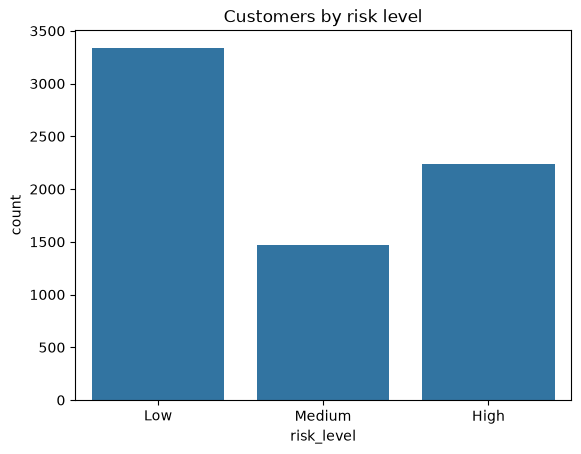

In [12]:
sns.countplot(data=pred, x="risk_level", order=["Low", "Medium", "High"])
plt.title("Customers by risk level")
plt.show()